In [6]:
import duckdb

db = duckdb.connect("data/trains.db")
db

## Phase 1 - data preparation

> Download data

In [7]:
DISTANCES_2022_URL = "https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv"
RAILWAY_STATIONS_2023_URL = "https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv"
TRAIN_DISRUPTION_BASE_URL = "https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-{year}.csv"
TRAIN_SERVICES_BASE_URL = "https://opendata.rijdendetreinen.nl/public/services/services-{year}.csv.gz"

In [28]:
import gzip
import shutil
import requests

DATA_DIR = "data"

def fetch_data(url: str, filename: str):
    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        if url.endswith(".gz"):
            with gzip.GzipFile(fileobj=r.raw) as gz, open(filename, "wb") as f:
                shutil.copyfileobj(gz, f)
        else:
            with open(filename, "wb") as f:
                shutil.copyfileobj(r.raw, f)


fetch_data(DISTANCES_2022_URL, f"{DATA_DIR}/distances_2022.csv")
fetch_data(RAILWAY_STATIONS_2023_URL, f"{DATA_DIR}/stations.csv")
for year in range(2011, 2024):
    fetch_data(TRAIN_DISRUPTION_BASE_URL.format(year=year), f"{DATA_DIR}/disruptions_{year}.csv")
for year in range(2019, 2026):
    fetch_data(TRAIN_SERVICES_BASE_URL.format(year=year), f"{DATA_DIR}/services_{year}.csv")

> Put stations data into stations table in DuckDB. This changes rarely, so we treat it as a almost constant file.


In [10]:
db.sql("""
CREATE TABLE IF NOT EXISTS stations AS
FROM 'data/stations.csv';
""")

In [12]:
db.sql("""
DESCRIBE stations;
""")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

In [23]:
db.sql("""
SELECT *
FROM stations
LIMIT 10;
""")

┌───────┬─────────┬─────────┬────────────┬──────────────────┬───────────────────────────┬───────────────────────────┬─────────┬───────────────────────────┬─────────────────┬─────────────────┐
│  id   │  code   │   uic   │ name_short │   name_medium    │         name_long         │           slug            │ country │           type            │     geo_lat     │     geo_lng     │
│ int64 │ varchar │  int64  │  varchar   │     varchar      │          varchar          │          varchar          │ varchar │          varchar          │     double      │     double      │
├───────┼─────────┼─────────┼────────────┼──────────────────┼───────────────────────────┼───────────────────────────┼─────────┼───────────────────────────┼─────────────────┼─────────────────┤
│   266 │ HT      │ 8400319 │ Den Bosch  │ 's-Hertogenbosch │ 's-Hertogenbosch          │ s-hertogenbosch           │ NL      │ knooppuntIntercitystation │        51.69048 │         5.29362 │
│   269 │ HTO     │ 8400320 │ Dn Bosch O

> Based on [DuckDB tutorial](https://duckdb.org/2024/05/31/analyzing-railway-traffic-in-the-netherlands#largest-distance-between-train-stations-in-the-netherlands), create tables distances and distances_long. We treat this similarly to stations table.

In [ ]:
# db.sql("DROP TABLE IF EXISTS distances")

db.sql("""
CREATE TABLE IF NOT EXISTS distances AS
FROM read_csv('data/distances_2022.csv', nullstr = 'XXX');
""")

In [ ]:
# db.sql("DROP TABLE IF EXISTS distances_long")

db.sql("""
CREATE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance;
""")

In [55]:
db.sql("""
SELECT station, other_station, distance
FROM distances_long
LIMIT 10;
""")

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
│ AC      │ AHZ           │       90 │
│ AC      │ AKL           │       71 │
│ AC      │ AKM           │      188 │
│ AC      │ ALM           │       32 │
│ AC      │ ALMB          │       38 │
│ AC      │ ALMM          │       31 │
│ AC      │ ALMO          │       40 │
├─────────┴───────────────┴──────────┤
│ 10 rows                  3 columns │
└────────────────────────────────────┘

> Put train disruptions into disruptions table in the Postgres database. We expect this data to change regularly, and thus treat it as a typical OLTP table.

In [21]:
DISRUPTIONS_DATA_PATHS = [
    f"data/disruptions_{year}.csv" for year in range(2011, 2024)
]


db.sql(f"""
CREATE TABLE IF NOT EXISTS disruptions AS
FROM read_csv({DISRUPTIONS_DATA_PATHS}, union_by_name=true);
""")

In [22]:
db.sql("""
DESCRIBE disruptions;
""")

┌──────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│     column_name      │ column_type │  null   │   key   │ default │  extra  │
│       varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ rdt_id               │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ns_lines             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines_id         │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_names    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_codes    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_nl             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_en             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ statistical_cause_nl │ VARCHAR     │ YES     │ NUL

In [ ]:
db.sql("""
SELECT *
FROM disruptions;
""")

┌────────┬──────────────────────────────────┬───────────────────────────────────────────────────────────────────────────────────┬──────────────┬───────────────────┬───────────────────┬─────────────────────────────┬───────────────────────────────┬─────────────────────────────┬───────────────────────────────┬──────────────────┬─────────────────────┬─────────────────────┬──────────────────┐
│ rdt_id │             ns_lines             │                                     rdt_lines                                     │ rdt_lines_id │ rdt_station_names │ rdt_station_codes │          cause_nl           │           cause_en            │    statistical_cause_nl     │     statistical_cause_en      │   cause_group    │     start_time      │      end_time       │ duration_minutes │
│ int64  │             varchar              │                                      varchar                                      │   varchar    │      varchar      │      varchar      │           varchar           │    

In [ ]:
db.sql("""
SELECT
    year(start_time) AS year,
    count(*) AS n_rows
FROM disruptions
GROUP BY year
ORDER BY year;
""")

┌───────┬────────┐
│ year  │ n_rows │
│ int64 │ int64  │
├───────┼────────┤
│  2011 │   1846 │
│  2012 │   2074 │
│  2013 │   2312 │
│  2014 │   2484 │
│  2015 │   2947 │
│  2016 │   3031 │
│  2017 │   4085 │
│  2018 │   5190 │
│  2019 │   5940 │
│  2020 │   4450 │
│  2021 │   4874 │
│  2022 │   5499 │
│  2023 │   5168 │
├───────┴────────┤
│    13 rows     │
└────────────────┘

> Transform train services CSV files into a single Parquet file. Make table services from it. We treat this as a big data batch input, created rarely but regularly for analytics purposes.

In [29]:
SERVICES_DATA_PATHS = [
    f"data/services_{year}.csv" for year in range(2019, 2026)
]

db.sql(f"""
COPY (
    SELECT *
    FROM read_csv({SERVICES_DATA_PATHS}, union_by_name=true)
) TO 'data/services.parquet' (FORMAT parquet, COMPRESSION zstd);
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [30]:
db.sql(f"""
CREATE TABLE IF NOT EXISTS services AS
FROM 'data/services.parquet';
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [31]:
db.sql("""
SELECT *
FROM services;
""")

┌────────────────┬──────────────┬──────────────┬─────────────────┬──────────────────────┬──────────────────────────────┬──────────────────────────┬───────────────────────┬─────────────┬───────────────────┬─────────────────────────┬─────────────────────┬────────────────────┬────────────────────────┬─────────────────────┬──────────────────────┬──────────────────────────┬──────────────────────┬───────────────────────┬──────────────────────┐
│ Service:RDT-ID │ Service:Date │ Service:Type │ Service:Company │ Service:Train number │ Service:Completely cancelled │ Service:Partly cancelled │ Service:Maximum delay │ Stop:RDT-ID │ Stop:Station code │    Stop:Station name    │  Stop:Arrival time  │ Stop:Arrival delay │ Stop:Arrival cancelled │ Stop:Departure time │ Stop:Departure delay │ Stop:Departure cancelled │ Stop:Platform change │ Stop:Planned platform │ Stop:Actual platform │
│     int64      │     date     │   varchar    │     varchar     │        int64         │           boolean         

## Phase 2 - queries

> How many trains departed from Amsterdam Central station overall?

In [ ]:
db.sql("""
SELECT COUNT(*) as cnt
FROM services
WHERE "Stop:Station name" = 'Amsterdam Centraal'
""")

┌─────────┐
│   cnt   │
│  int64  │
├─────────┤
│ 3066833 │
└─────────┘

> Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay.

In [36]:
db.sql("""
SELECT "Service:Type", AVG("Stop:Arrival delay") as avg_delay
FROM services
GROUP BY "Service:Type"
ORDER BY "avg_delay" DESC;
""")

┌────────────────────┬────────────────────┐
│    Service:Type    │     avg_delay      │
│      varchar       │       double       │
├────────────────────┼────────────────────┤
│ Alpen Express      │  31.84254143646409 │
│ Krokus Express     │ 18.304347826086957 │
│ European Sleeper   │ 14.262589044460821 │
│ Nightjet           │   9.42391097403092 │
│ ICE                │   7.76692176533566 │
│ Eurostar           │  7.302104678961749 │
│ ICE International  │  5.482790573052148 │
│ Thalys             │ 5.3961896909446025 │
│ Int. Trein         │  4.677560708417016 │
│ Nachttrein         │ 3.8370501214396113 │
│     ·              │                 ·  │
│     ·              │                 ·  │
│     ·              │                 ·  │
│ Tram i.p.v. trein  │                0.0 │
│ Metro              │                0.0 │
│ Tram ipv trein     │                0.0 │
│ OV-bus ipv trein   │                0.0 │
│ Metro i.p.v. trein │                0.0 │
│ stoptrein          │          

> What was the most common disruption cause in different years? [MODE](https://duckdb.org/docs/current/sql/functions/aggregates#modex) function may be useful.

In [39]:
db.sql("""
SELECT YEAR("start_time") as year, MODE("cause_en") as cause
FROM disruptions
GROUP BY year
ORDER BY year
""")

┌───────┬───────────────────┐
│ year  │       cause       │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
├───────┴───────────────────┤
│ 13 rows         2 columns │
└───────────────────────────┘

> How many trains started their overall service in any Amsterdam station?

In [41]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS trains_started_in_amsterdam
FROM services
WHERE "Stop:Station name" LIKE 'Amsterdam%' AND "Stop:Arrival time" IS NULL;
""")

┌─────────────────────────────┐
│ trains_started_in_amsterdam │
│            int64            │
├─────────────────────────────┤
│                     1277350 │
└─────────────────────────────┘

> What fraction of services was run to final destinations outside the Netherlands?

In [50]:
db.sql("""
SELECT
    COUNT(DISTINCT services."Service:RDT-ID")
    / (SELECT COUNT(DISTINCT "Service:RDT-ID") FROM services)
    AS fraction_outside_netherlands
FROM services
JOIN stations
    ON services."Stop:Station code" = stations."code"
WHERE stations."country" <> 'NL'
  AND services."Stop:Departure time" IS NULL
""")

┌──────────────────────────────┐
│ fraction_outside_netherlands │
│            double            │
├──────────────────────────────┤
│          0.03733940368806168 │
└──────────────────────────────┘

> What is the largest distance between stations in the Netherlands (code NL)?

In [70]:
db.sql("""
select d.station, d.other_station, d.distance as max_distance
from distances_long as d
join stations as start_station
    on d.station = start_station.code
join stations as end_station
    on d.station = end_station.code
where start_station.country = 'NL' and end_station.country = 'NL'
order by max_distance desc
limit 1
""")

┌─────────┬───────────────┬──────────────┐
│ Station │ other_station │ max_distance │
│ varchar │    varchar    │    int64     │
├─────────┼───────────────┼──────────────┤
│ VS      │ LEER          │          450 │
└─────────┴───────────────┴──────────────┘

> Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.

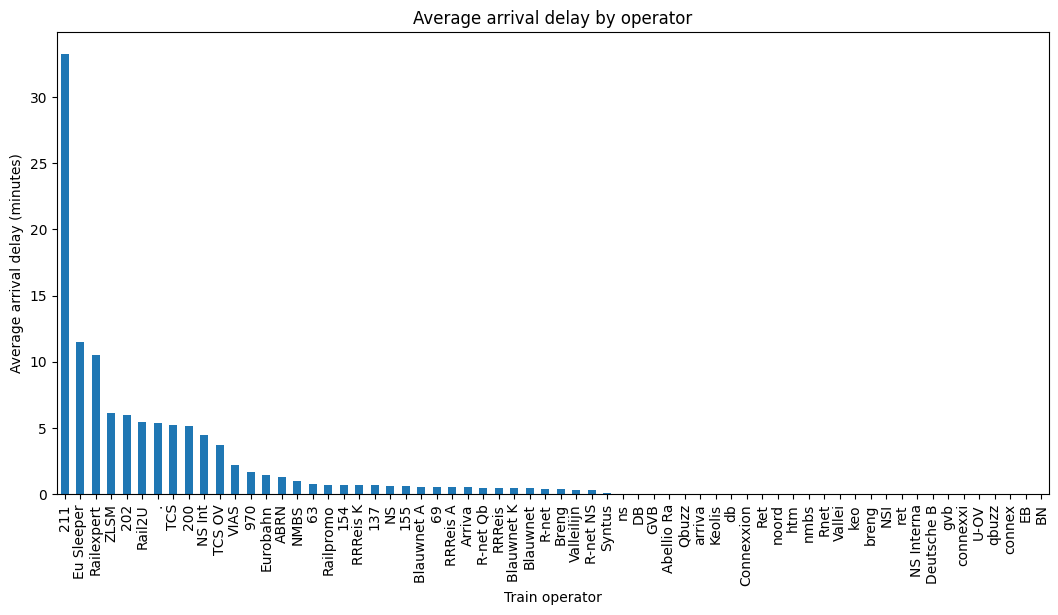

In [100]:
import matplotlib.pyplot as plt

delays_df = db.sql("""
select "Service:Company" as company, avg(coalesce("Stop:Arrival delay", 0)) as avg_arrival_delay
from services
group by "Service:Company"
order by avg_arrival_delay desc
""").df()

ax = delays_df.plot.bar(
    x="company",
    y="avg_arrival_delay",
    figsize=(max(6, len(delays_df) * 0.2), 6),
    xlabel="Train operator",
    ylabel="Average arrival delay (minutes)",
    title="Average arrival delay by operator",
    legend=False,
)

plt.show()

> How many services were disrupted in different years? Make a line plot.

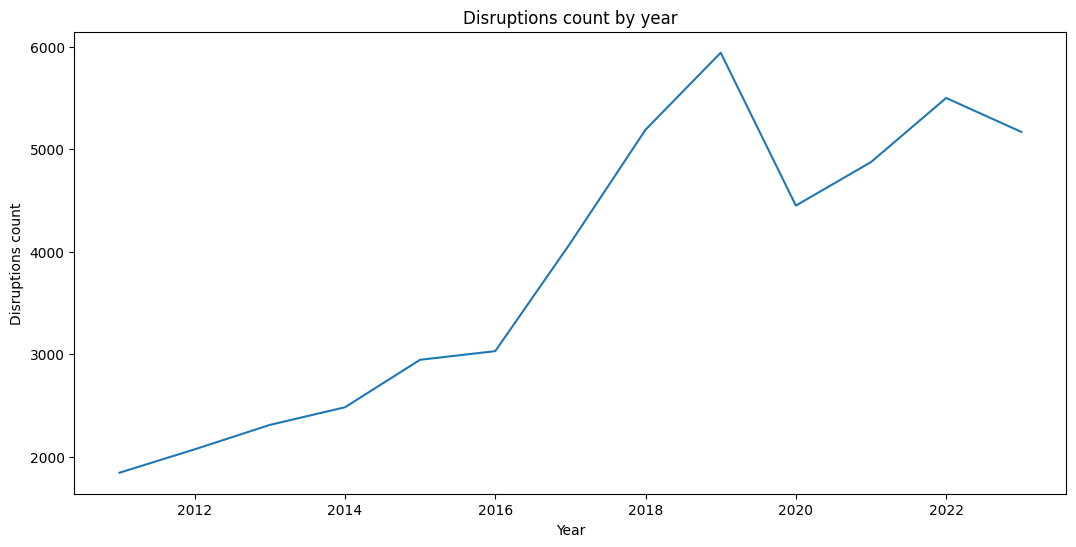

In [102]:
disruptions_df = db.sql("""
select year(start_time) as year, count(*) as disruptions_count
from disruptions
group by year
order by year
""").df()

ax = disruptions_df.plot.line(
    x="year",
    y="disruptions_count",
    figsize=(max(6, len(delays_df) * 0.2), 6),
    xlabel="Year",
    ylabel="Disruptions count",
    title="Disruptions count by year",
    legend=False,
)

plt.show()

> What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.

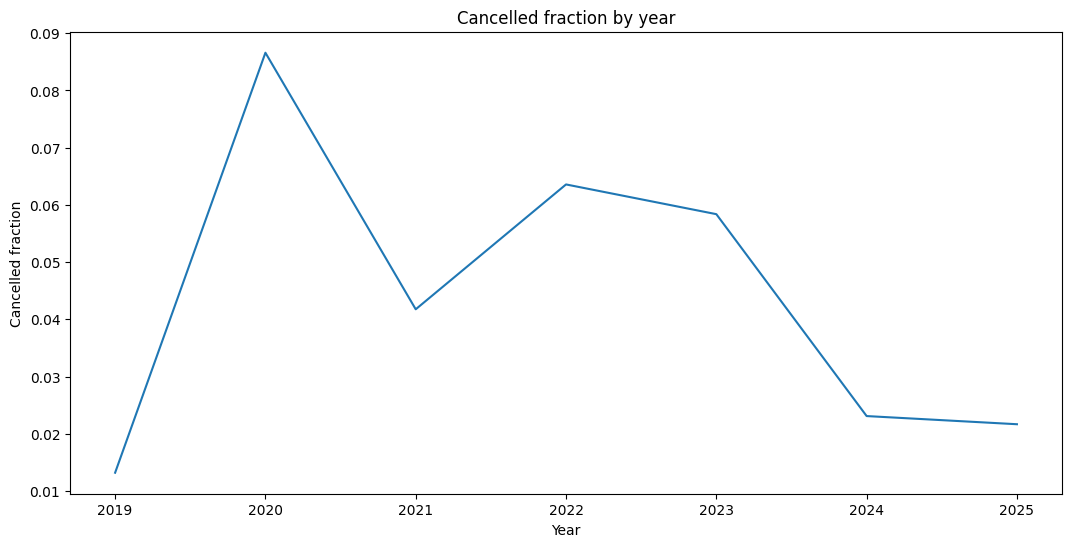

In [109]:
cancelled_df = db.sql("""
select 
    year("Service:Date") as year,
    count(distinct "Service:RDT-ID") filter (where "Service:Completely cancelled" = true)
    / count(distinct "Service:RDT-ID") as cancelled_fraction
from services
group by year
order by year
""").df()

ax = cancelled_df.plot.line(
    x="year",
    y="cancelled_fraction",
    figsize=(max(6, len(delays_df) * 0.2), 6),
    xlabel="Year",
    ylabel="Cancelled fraction",
    title="Cancelled fraction by year",
    legend=False,
)

plt.show()

## Phase 3 - add additional table

> Create table station_connections, with columns Service:RDT-ID, start_station_code and end_station_code (pair of stations on a route), and distance between them. Note that you should deduplicate the data on station codes, so that every station pair appears only once. Create temporary tables, use a subquery, or any other similar techniques if necessary.

In [ ]:
db.sql("""
create or replace table station_connections as
with ordered_stops as (
    select
        "Service:RDT-ID",
        "Stop:Station code" as start_station_code,
        lead("Stop:Station code") over (
            partition by "Service:RDT-ID"
            order by "Stop:Departure time" nulls last
        ) as end_station_code
    from services
),
connections as (
    select distinct
        "Service:RDT-ID",
        start_station_code,
        end_station_code
    from ordered_stops
    where end_station_code is not null
)
select
    c."Service:RDT-ID",
    c.start_station_code,
    c.end_station_code,
    d.distance
from connections as c
left join distances_long as d
    on c.start_station_code = d.station
   and c.end_station_code = d.other_station
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

> 

> What is the largest distance between a pair of stations?

In [122]:
db.sql("""
select distinct start_station_code, end_station_code, distance
from station_connections
where distance is not null
order by distance desc
limit 1
""")

┌────────────────────┬──────────────────┬──────────┐
│ start_station_code │ end_station_code │ distance │
│      varchar       │     varchar      │  int64   │
├────────────────────┼──────────────────┼──────────┤
│ VS                 │ STV              │      421 │
└────────────────────┴──────────────────┴──────────┘

> Plot a histogram of inter-station distances run by trains.


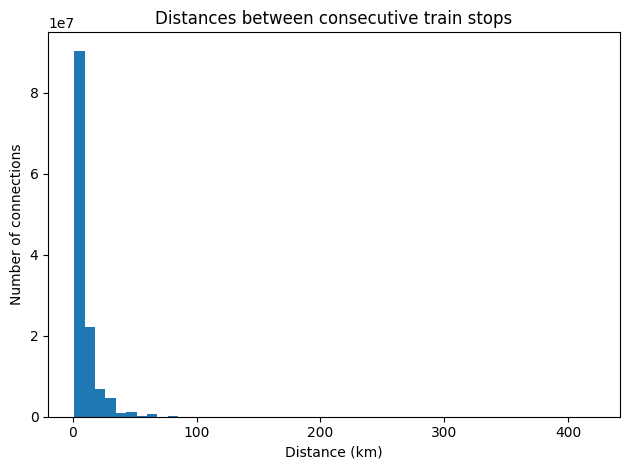

In [127]:
inter_station_distances_df = db.sql("""
select distance
from station_connections
where distance is not null
""").df()

ax = inter_station_distances_df["distance"].plot.hist(
    bins=50,
    title="Distances between consecutive train stops",
)

ax.set_xlabel("Distance (km)")
ax.set_ylabel("Number of connections")

plt.tight_layout()
plt.show()